# Tugas Besar 2 IF3170 Inteligensi Artifisial

## Group 20

- Faiq Azzam Nafidz (13524003)
- Mikhael Benrael Tampubolon (13524009)
- Muhammad Nafis Habibi (13524018)
- Syaqina Octavia Rizha (13524088)
- Muhammad Rafi Akbar (13524128)

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)

---

# 1. Introduction <a name="1"></a>

---

## Overview & Aim

Notebook ini membangun pipeline klasifikasi pembatalan reservasi akomodasi (`is_canceled`) secara modular, bebas *data leakage*, dan **sepenuhnya menggunakan 5 algoritma klasik implementasi *from-scratch* tanpa ensemble**:
**KNN, Decision Tree Learning (DTL), Logistic Regression, SVM, dan Naive Bayes**.

- **Dataset**: 27.373 baris latih (`train.csv`) dan 6.844 baris uji (`test.csv`).
- **Metrik Evaluasi**: **Macro F1-Score** (`f1_score(..., average='macro')`).
- **Pendekatan**: EDA komprehensif, feature engineering domain & temporal, `ColumnTransformer` + `Pipeline`, tuning hyperparameter dengan `GridSearchCV` (`scikit-learn`), pelatihan & perbandingan 5 model *from-scratch*, serta submission menggunakan model *from-scratch* terbaik.

---

# 2. Initialization <a name="2"></a>

---

## Environment Setup & Imports

In [ ]:
# %pip install -q numpy pandas scikit-learn matplotlib seaborn graphviz

In [3]:
import os
import sys
import pickle
import random
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

ROOT_DIR = Path.cwd() if (Path.cwd() / 'input').exists() else Path.cwd().parent
SRC_DIR = ROOT_DIR / 'src' if (ROOT_DIR / 'src' / 'scratch_model').exists() else ROOT_DIR
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from scratch_model.knn import KNN as sm_KNN
from scratch_model.dtl import DecisionTreeClassifier as sm_DecisionTreeClassifier
from scratch_model.logistic_regression import LogisticRegression as sm_LogisticRegression
from scratch_model.svm import SVM as sm_SVM
from scratch_model.naive_bayes import NaiveBayes as sm_NaiveBayes

## Settings & Reproducibility

In [4]:
class Settings:
    SEED          = 42
    PROJECT_ROOT  = ROOT_DIR
    DATA_DIR      = ROOT_DIR / 'input'
    OUTPUT_DIR    = ROOT_DIR / 'output'
    MODEL_DIR     = ROOT_DIR / 'output' / 'saved_models'
    TARGET_COLUMN = 'is_canceled'
    ID_COLUMN     = 'id'

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CFG.MODEL_DIR.mkdir(parents=True, exist_ok=True)

def set_seed(seed: int) -> None:
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

set_seed(CFG.SEED)

## Data Loading

In [5]:
def load_data(data_dir: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    train_df = pd.read_csv(data_dir / 'train.csv', dtype={CFG.ID_COLUMN: str})
    test_df  = pd.read_csv(data_dir / 'test.csv', dtype={CFG.ID_COLUMN: str})
    print(f'Train: {train_df.shape} | Test: {test_df.shape}')
    print('Target proportion:', train_df[CFG.TARGET_COLUMN].value_counts(normalize=True).round(4).to_dict())
    return train_df, test_df

train_df, test_df = load_data(CFG.DATA_DIR)
display(train_df.head())

Train: (27373, 19) | Test: (6844, 18)
Target proportion: {0: 0.6723, 1: 0.3277}


,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
0,57152f82,2.0,NaN,1,2,Breakfast,0.0,Type B,88.0,2024,4,3,Offline Agent,0,0,0,1330000.0,0.0,1
1,af2ec71b,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,1,Offline Agent,0,0,0,NaN,0.0,0
2,5d5469ab,3.0,0.0,1,2,Breakfast,0.0,Type G,209.0,2024,8,28,Online Travel Agent,0,0,0,2099000.0,0.0,1
3,d2df0369,2.0,1.0,2,1,Breakfast,0.0,Type G,93.0,2024,8,13,Online Travel Agent,0,0,0,1693000.0,2.0,0
4,91d253db,2.0,0.0,0,1,Room Only,0.0,Type B,14.0,2024,9,1,Online Travel Agent,0,0,0,2010000.0,2.0,0


---

# 3. Data Understanding <a name="3"></a>

---

## Visualisasi & Kualitas Data

EDA di bagian ini dibagi menjadi beberapa tahapan:

- **3.1 Struktur Data & Distribusi Target**: tipe kolom, nilai unik, nilai kosong, duplikat, dan proporsi kelas `is_canceled`.
- **3.2 Statistik Deskriptif & Distribusi Fitur Numerik**: ringkasan numerik (ditambah skewness & kurtosis) serta histogram tiap fitur. Kolom diskret ditampilkan sebagai bar tanpa KDE, sedangkan kolom kontinu memakai KDE.
- **3.3 Korelasi Antar Fitur**: heatmap Pearson antar fitur numerik dan daftar korelasi terhadap target.
- **3.4 Kualitas Data & Perbandingan Missing Value**: perbandingan nilai kosong train vs test serta pemeriksaan *cancel rate* saat nilai kosong / nol.
- **3.5 Fitur Kategorikal terhadap Target**: tabel proporsi target per kategori dan *stacked bar chart*.

### 3.1 Struktur Data & Distribusi Target

Baris duplikat (tanpa kolom id): 64


,Tipe,Nilai Unik,Kosong,Kosong (%)
id,object,27373,0,0.00
num_adults,float64,5,809,2.96
num_children,float64,6,3035,11.09
weekend_nights,int64,8,0,0.00
weekday_nights,int64,18,0,0.00
meal_package,object,4,1760,6.43
needs_parking,float64,2,1082,3.95
room_category,object,7,1002,3.66
days_before_arrival,float64,407,1123,4.10
arrival_year,int64,2,0,0.00


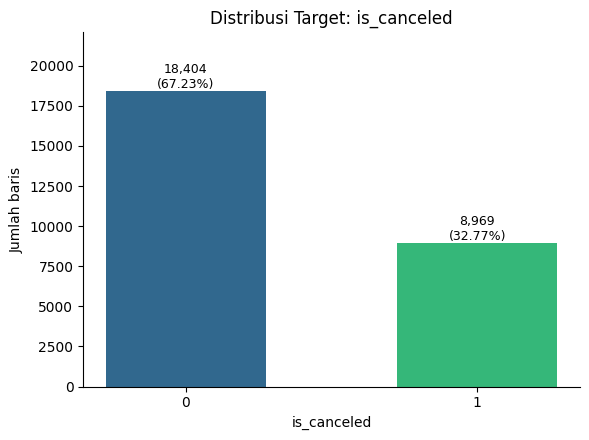

In [6]:
def summarize_dataset(df: pd.DataFrame) -> pd.DataFrame:
    summary = pd.DataFrame({
        'Tipe': df.dtypes.astype(str),
        'Nilai Unik': df.nunique(),
        'Kosong': df.isna().sum(),
        'Kosong (%)': (df.isna().mean() * 100).round(2),
    })
    dup_rows = df.drop(columns=[CFG.ID_COLUMN]).duplicated().sum()
    print(f'Baris duplikat (tanpa kolom {CFG.ID_COLUMN}): {dup_rows}')
    return summary

def plot_target_distribution(df: pd.DataFrame, target_col: str = CFG.TARGET_COLUMN) -> None:
    counts = df[target_col].value_counts().sort_index()
    props = df[target_col].value_counts(normalize=True).sort_index() * 100

    fig, ax = plt.subplots(figsize=(6, 4.5))
    bars = ax.bar(counts.index.astype(str), counts.values, width=0.55, color=sns.color_palette('viridis', len(counts)))
    for bar, prop in zip(bars, props.values):
        ax.text(
            bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f'{int(bar.get_height()):,}\n({prop:.2f}%)',
            ha='center', va='bottom', fontsize=9,
        )
    ax.set_title(f'Distribusi Target: {target_col}')
    ax.set_xlabel(target_col)
    ax.set_ylabel('Jumlah baris')
    ax.set_ylim(0, counts.max() * 1.2)
    sns.despine(ax=ax)
    plt.tight_layout()
    plt.show()

display(summarize_dataset(train_df))
plot_target_distribution(train_df)

### 3.2 Statistik Deskriptif & Distribusi Fitur Numerik

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
num_adults,26564.0,1.845,0.518,0.0,2.0,2.0,2.0,4.0,-0.339,0.872
num_children,24338.0,0.117,0.426,0.0,0.0,0.0,0.0,10.0,4.663,39.072
weekend_nights,27373.0,0.815,0.875,0.0,0.0,1.0,2.0,7.0,0.745,0.335
weekday_nights,27373.0,2.207,1.422,0.0,1.0,2.0,3.0,17.0,1.648,8.111
needs_parking,26291.0,0.030,0.171,0.0,0.0,0.0,0.0,1.0,5.491,28.149
days_before_arrival,26250.0,85.379,85.970,0.0,17.0,58.0,126.0,448.0,1.296,1.213
arrival_year,27373.0,2023.820,0.384,2023.0,2024.0,2024.0,2024.0,2024.0,-1.667,0.779
arrival_month,27373.0,7.400,3.075,1.0,5.0,8.0,10.0,12.0,-0.344,-0.940
arrival_day,27373.0,15.538,8.773,1.0,8.0,16.0,23.0,31.0,0.032,-1.163
is_returning_guest,27373.0,0.025,0.157,0.0,0.0,0.0,0.0,1.0,6.063,34.761


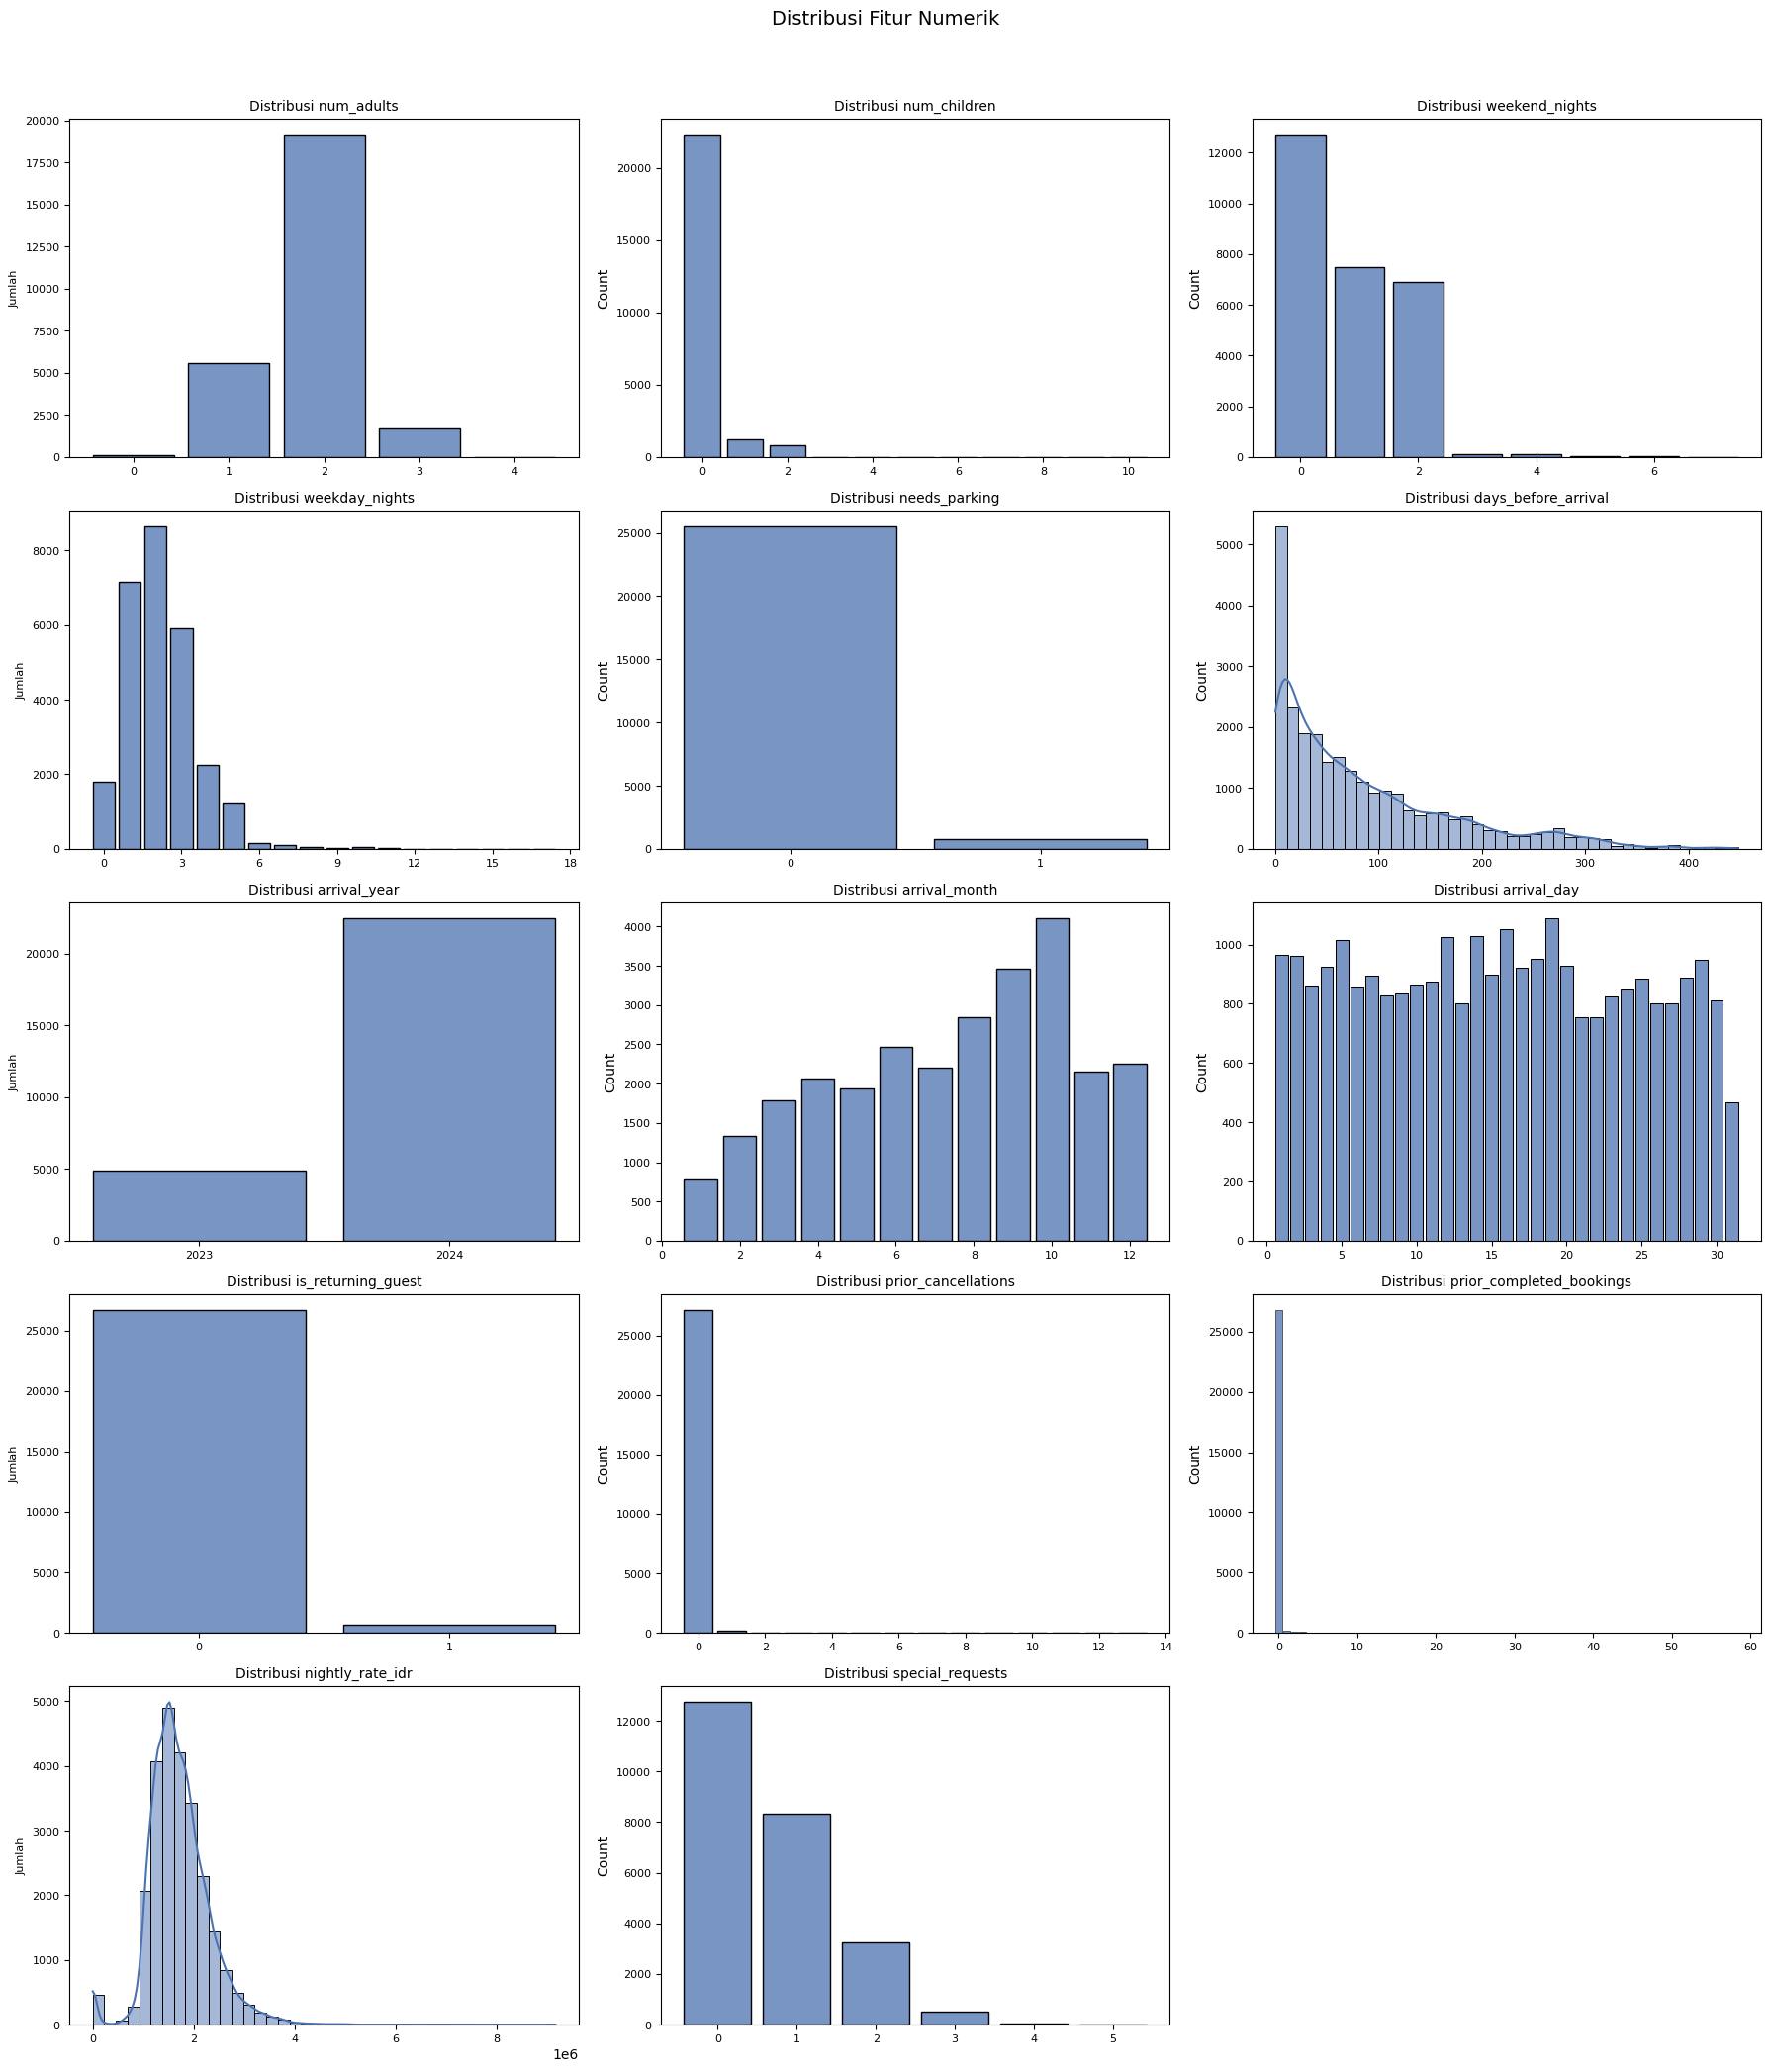

In [7]:
def describe_numeric(df: pd.DataFrame) -> pd.DataFrame:
    num_df = df.select_dtypes(include=np.number)
    desc = num_df.describe().T
    desc['skew'] = num_df.skew()
    desc['kurtosis'] = num_df.kurtosis()
    return desc.round(3)

def plot_numeric_distributions(df: pd.DataFrame, target_col: str = CFG.TARGET_COLUMN, n_cols: int = 3) -> None:
    num_cols = [c for c in df.select_dtypes(include=np.number).columns if c != target_col]
    n_rows = int(np.ceil(len(num_cols) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4.2 * n_rows))
    axes = np.array(axes).flatten()

    for ax, col in zip(axes, num_cols):
        is_discrete = pd.api.types.is_integer_dtype(df[col]) or df[col].nunique() <= 12
        if is_discrete:
            sns.histplot(data=df, x=col, discrete=True, shrink=0.85, color='#4C72B0', ax=ax)
            ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=8))
        else:
            sns.histplot(data=df, x=col, bins=40, kde=True, color='#4C72B0', ax=ax)
        ax.set_title(f'Distribusi {col}', fontsize=10)
        ax.set_xlabel('')
        ax.tick_params(labelsize=8)

    for ax in axes[:len(num_cols):n_cols]:
        ax.set_ylabel('Jumlah', fontsize=8)
    for ax in axes[len(num_cols):]:
        ax.set_visible(False)

    fig.suptitle('Distribusi Fitur Numerik', fontsize=14, y=0.995)
    fig.tight_layout(rect=(0, 0, 1, 0.975))
    plt.show()

display(describe_numeric(train_df))
plot_numeric_distributions(train_df)

### 3.3 Korelasi Antar Fitur

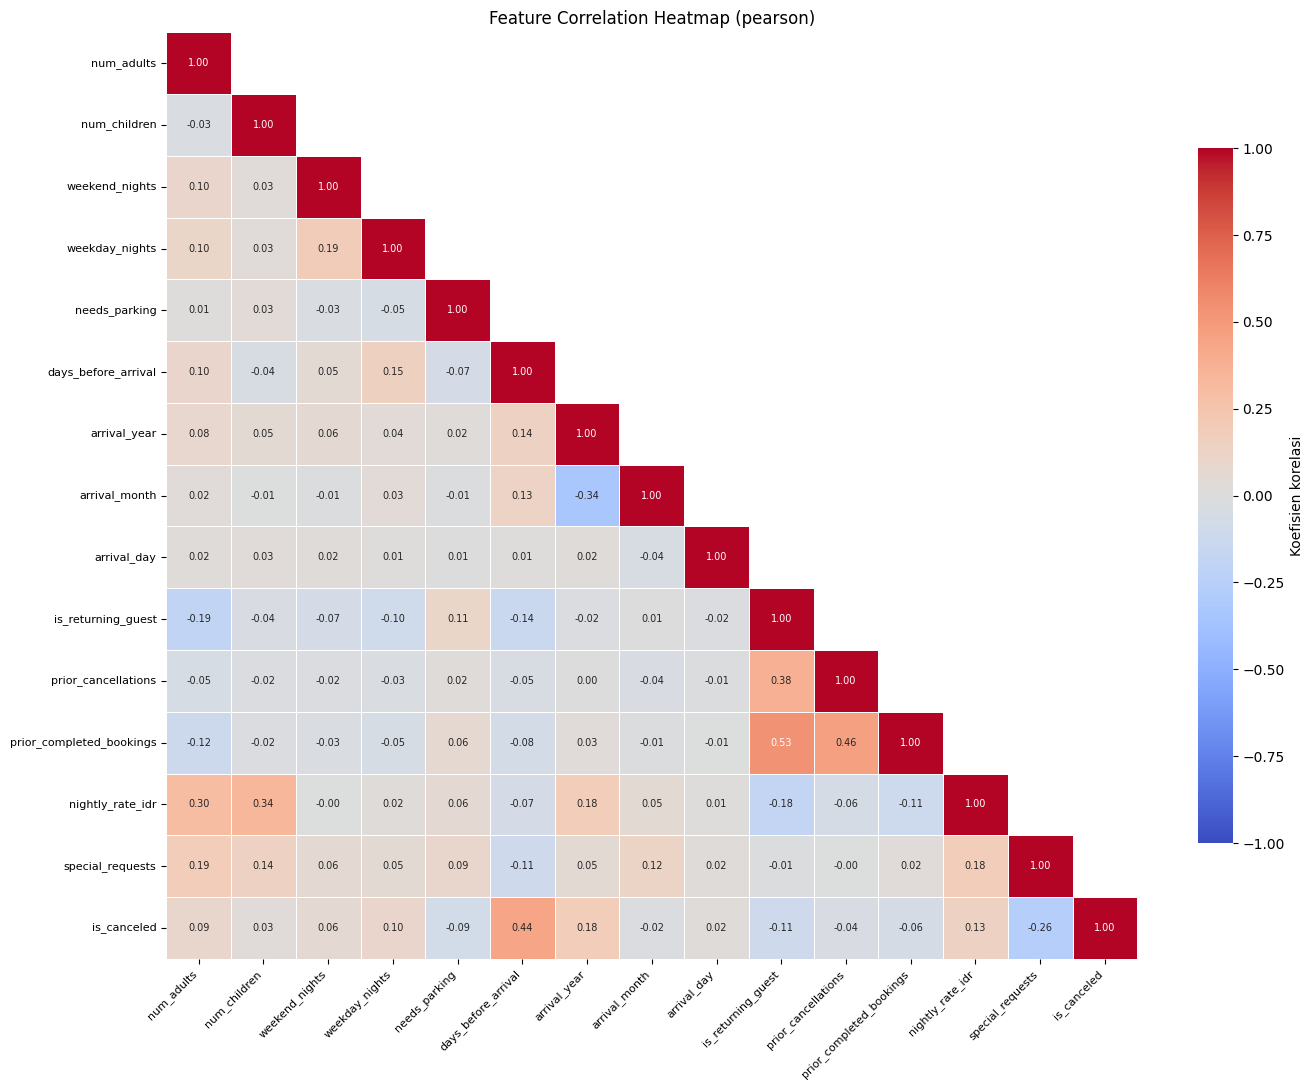

Korelasi terhadap target (urut dari positif terbesar):


,korelasi
days_before_arrival,0.4403
arrival_year,0.1798
nightly_rate_idr,0.1341
weekday_nights,0.0972
num_adults,0.0884
weekend_nights,0.0608
num_children,0.0309
arrival_day,0.0200
arrival_month,-0.0159
prior_cancellations,-0.0350


In [8]:
def plot_correlation_heatmap(df: pd.DataFrame, target_col: str = CFG.TARGET_COLUMN, method: str = 'pearson') -> pd.DataFrame:
    corr = df.select_dtypes(include=np.number).corr(method=method)
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

    plt.figure(figsize=(14, 11))
    sns.heatmap(
        corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
        center=0, vmin=-1, vmax=1, linewidths=0.5,
        annot_kws={'size': 7}, cbar_kws={'shrink': 0.75, 'label': 'Koefisien korelasi'},
    )
    plt.title(f'Feature Correlation Heatmap ({method})')
    plt.xticks(rotation=45, ha='right', fontsize=8)
    plt.yticks(fontsize=8)
    plt.tight_layout()
    plt.show()

    print('Korelasi terhadap target (urut dari positif terbesar):')
    display(corr[target_col].drop(target_col).sort_values(ascending=False).round(4).to_frame('korelasi'))
    return corr

correlation_matrix = plot_correlation_heatmap(train_df)

### 3.4 Kualitas Data & Perbandingan Missing Value

nightly_rate_idr == 0 -> count=413, cancel_rate=0.0073


,Column,Train NA (%),Test NA (%),Cancel Rate (NA)
0,num_adults,2.96,2.63,0.3350
1,num_children,11.09,10.91,0.3282
2,weekend_nights,0.00,0.00,NaN
3,weekday_nights,0.00,0.00,NaN
4,meal_package,6.43,6.46,0.3193
5,needs_parking,3.95,3.61,0.3124
6,room_category,3.66,3.54,0.3483
7,days_before_arrival,4.10,4.24,0.3117
8,arrival_year,0.00,0.00,NaN
9,arrival_month,0.00,0.00,NaN


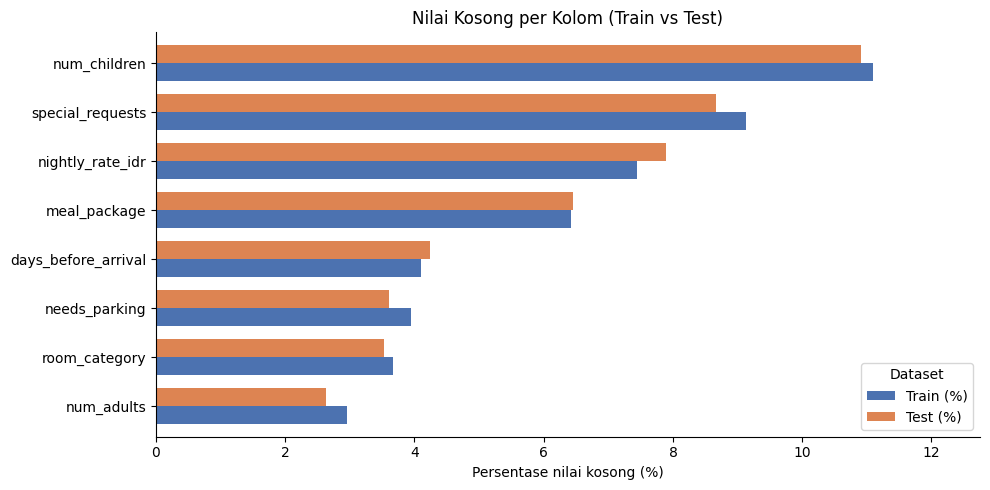

In [9]:
def check_quality(train_df: pd.DataFrame, test_df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for col in train_df.columns.drop([CFG.ID_COLUMN, CFG.TARGET_COLUMN]):
        na_tr = train_df[col].isna().mean() * 100
        na_te = test_df[col].isna().mean() * 100
        cr_na = train_df.loc[train_df[col].isna(), CFG.TARGET_COLUMN].mean() if na_tr > 0 else np.nan
        rows.append({
            'Column': col,
            'Train NA (%)': round(na_tr, 2),
            'Test NA (%)': round(na_te, 2),
            'Cancel Rate (NA)': round(cr_na, 4) if pd.notna(cr_na) else np.nan,
        })
    zero_rate = train_df[train_df['nightly_rate_idr'] == 0]
    print(f'nightly_rate_idr == 0 -> count={len(zero_rate)}, cancel_rate={zero_rate[CFG.TARGET_COLUMN].mean():.4f}')
    return pd.DataFrame(rows)

def plot_missing_values(train_df: pd.DataFrame, test_df: pd.DataFrame) -> None:
    missing = pd.DataFrame({
        'Train (%)': train_df.isna().mean() * 100,
        'Test (%)': test_df.isna().mean() * 100,
    })
    missing = missing[missing.max(axis=1) > 0].sort_values('Train (%)')

    ax = missing.plot(kind='barh', figsize=(10, 5), width=0.75, color=['#4C72B0', '#DD8452'])
    ax.set_xlim(0, missing.max().max() * 1.15)
    ax.set_xlabel('Persentase nilai kosong (%)')
    ax.set_title('Nilai Kosong per Kolom (Train vs Test)')
    ax.legend(title='Dataset')
    sns.despine(ax=ax)
    plt.tight_layout()
    plt.show()

display(check_quality(train_df, test_df))
plot_missing_values(train_df, test_df)

### 3.5 Hubungan Target dengan Fitur Kategorikal

Proporsi target per meal_package (baris = kategori)


is_canceled,n,0,1
meal_package,,,
Half Board,2242,54.06,45.94
Room Only,3713,66.20,33.80
Missing,1760,68.07,31.93
Breakfast,19654,68.86,31.14
Full Board,4,75.00,25.00


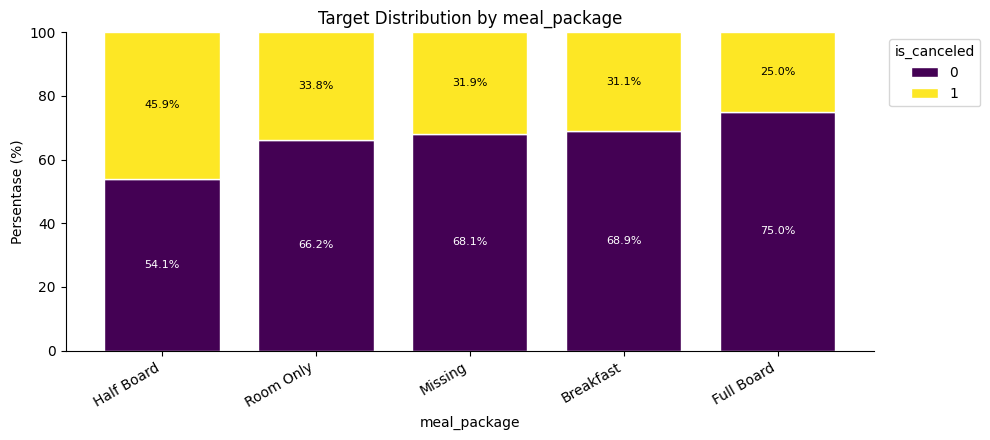

Proporsi target per room_category (baris = kategori)


is_canceled,n,0,1
room_category,,,
Type A,699,57.37,42.63
Missing,1002,65.17,34.83
Type G,4396,65.81,34.19
Type D,514,67.12,32.88
Type B,20447,67.86,32.14
Type E,7,71.43,28.57
Type C,189,75.13,24.87
Type F,119,75.63,24.37


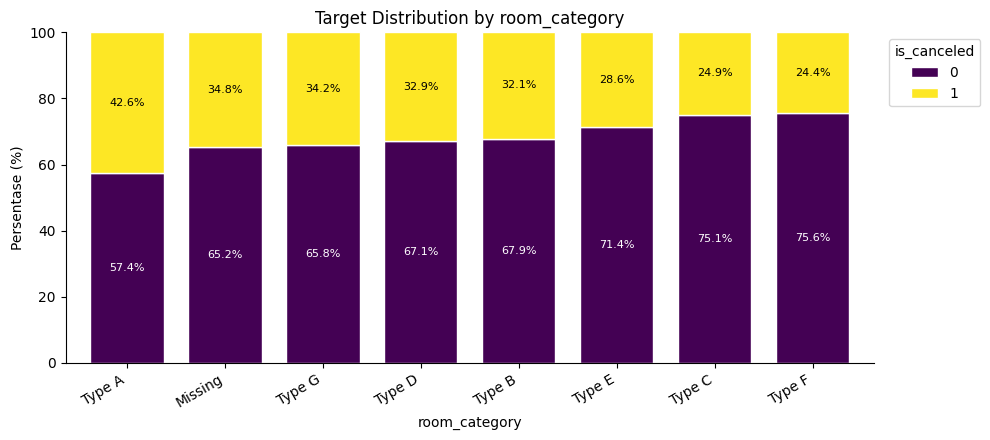

Proporsi target per booking_channel (baris = kategori)


is_canceled,n,0,1
booking_channel,,,
Online Travel Agent,17511,63.63,36.37
Airline,88,69.32,30.68
Offline Agent,7960,69.85,30.15
Corporate,1513,88.50,11.50
Complimentary,301,100.00,0.00


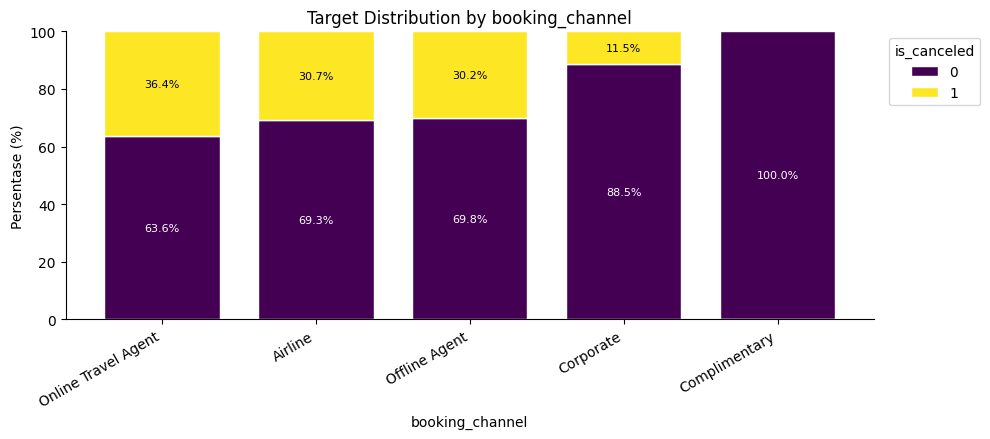

In [10]:
def plot_categorical_target(df: pd.DataFrame, target_col: str = CFG.TARGET_COLUMN) -> None:
    cat_cols = [
        col for col in df.columns
        if col not in (CFG.ID_COLUMN, target_col) and not pd.api.types.is_numeric_dtype(df[col])
    ]

    for col in cat_cols:
        counts = pd.crosstab(df[col].fillna('Missing'), df[target_col])
        proportion = counts.div(counts.sum(axis=1), axis=0) * 100
        if 1 in proportion.columns:
            order = proportion[1].sort_values(ascending=False).index
            counts, proportion = counts.loc[order], proportion.loc[order]

        table = proportion.copy()
        table.insert(0, 'n', counts.sum(axis=1))
        print(f'Proporsi target per {col} (baris = kategori)')
        display(table.round(2))

        ax = proportion.plot(
            kind='bar', stacked=True, figsize=(10, 4.5),
            colormap='viridis', width=0.75, edgecolor='white',
        )
        for pos, container in enumerate(ax.containers):
            labels = [f'{p.get_height():.1f}%' if p.get_height() >= 5 else '' for p in container]
            ax.bar_label(container, labels=labels, label_type='center', fontsize=8, color='white' if pos == 0 else 'black')
        ax.set_title(f'Target Distribution by {col}')
        ax.set_xlabel(col)
        ax.set_ylabel('Persentase (%)')
        ax.set_ylim(0, 100)
        ax.legend(title=target_col, bbox_to_anchor=(1.01, 1), loc='upper left')
        plt.xticks(rotation=30, ha='right')
        sns.despine(ax=ax)
        plt.tight_layout()
        plt.show()

plot_categorical_target(train_df)

---

# 4. Training and Validation Split <a name="4"></a>

---

In [11]:
def split_data(train_df: pd.DataFrame, target_col: str = CFG.TARGET_COLUMN, test_size: float = 0.2, seed: int = CFG.SEED):
    X = train_df.drop(columns=[CFG.ID_COLUMN, target_col]).copy()
    y = train_df[target_col].astype(int).copy()
    X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=test_size, stratify=y, random_state=seed)
    print(f'Split -> X_train: {X_tr.shape}, X_val: {X_va.shape}')
    return X, y, X_tr, X_va, y_tr, y_va

X_full_raw, y_full, X_train_raw, X_val_raw, y_train, y_val = split_data(train_df)
X_test_raw = test_df.drop(columns=[CFG.ID_COLUMN]).copy()

Split -> X_train: (21898, 17), X_val: (5475, 17)


---

# 5. Data Preparation <a name="5"></a>

---

## Data Cleaning & Feature Engineering

Dari hasil EDA dibuat keputusan berikut:
1. Pertahankan `arrival_day` untuk membentuk fitur temporal (`arrival_days_since_start`, `arrival_dow`, `booking_days_since_start`).
2. Pertahankan `nightly_rate_idr == 0` (*cancel rate* 0,73%) dan tambahkan indikator `is_zero_rate`.
3. Hindari IQR clipping global karena 7 kolom numerik memiliki `IQR = 0`.
4. Tambahkan indikator `special_requests_isna` (MNAR) dan interaksi `ota_no_special_req`.
5. Nilai pengisi sementara (`num_adults`, `num_children`, `days_before_arrival`, `special_requests`) dihitung dari median data latih agar terhindar dari *data leakage*.

In [ ]:
NON_NEGATIVE_COLS = [
    'nightly_rate_idr', 'days_before_arrival', 'num_adults', 'num_children',
    'weekend_nights', 'weekday_nights', 'special_requests',
    'prior_cancellations', 'prior_completed_bookings',
]

def clean_data(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    for col in NON_NEGATIVE_COLS:
        if col in df.columns:
            df.loc[df[col] < 0, col] = np.nan
    return df

def fit_fill_medians(train_df: pd.DataFrame) -> dict[str, float]:
    cols = ['num_adults', 'num_children', 'days_before_arrival', 'special_requests']
    return {col: float(train_df[col].median()) for col in cols}

def add_features(df: pd.DataFrame, fill_medians: dict[str, float]) -> pd.DataFrame:
    df = df.copy()

    df['special_requests_isna'] = df['special_requests'].isna().astype(int)
    df['total_nights'] = df['weekend_nights'] + df['weekday_nights']
    df['is_zero_nights'] = (df['total_nights'] == 0).astype(int)
    df['total_guests'] = df['num_adults'].fillna(fill_medians['num_adults']) + df['num_children'].fillna(fill_medians['num_children'])
    df['is_zero_rate'] = (df['nightly_rate_idr'] == 0).astype(int)
    df['total_cost_est'] = df['nightly_rate_idr'] * np.maximum(df['total_nights'], 1)
    df['prior_cancel_ratio'] = df['prior_cancellations'] / (df['prior_cancellations'] + df['prior_completed_bookings'] + 1.0)

    df['log_days_before'] = np.log1p(df['days_before_arrival'].clip(lower=0))
    df['log_nightly_rate'] = np.log1p(df['nightly_rate_idr'].clip(lower=0))

    sr_filled = df['special_requests'].fillna(fill_medians['special_requests'])
    df['ota_no_special_req'] = ((df['booking_channel'] == 'Online Travel Agent') & (sr_filled == 0)).astype(int)

    arrival_dt = pd.to_datetime(dict(year=df['arrival_year'], month=df['arrival_month'], day=df['arrival_day']))
    ref_date = pd.Timestamp('2023-07-01')
    df['arrival_days_since_start'] = (arrival_dt - ref_date).dt.days
    df['arrival_dow'] = arrival_dt.dt.day_of_week
    df['month_sin'] = np.sin(2 * np.pi * df['arrival_month'] / 12.0)
    df['month_cos'] = np.cos(2 * np.pi * df['arrival_month'] / 12.0)

    lead_filled = df['days_before_arrival'].fillna(fill_medians['days_before_arrival'])
    booking_dt = arrival_dt - pd.to_timedelta(lead_filled, unit='D')
    df['booking_days_since_start'] = (booking_dt - ref_date).dt.days
    return df

train_clean = clean_data(X_train_raw)
split_medians = fit_fill_medians(train_clean)
X_train = add_features(train_clean, split_medians)
X_val   = add_features(clean_data(X_val_raw), split_medians)

full_clean = clean_data(X_full_raw)
full_medians = fit_fill_medians(full_clean)
X_full = add_features(full_clean, full_medians)
X_test = add_features(clean_data(X_test_raw), full_medians)

print(f'Feature shape -> X_train: {X_train.shape}, X_val: {X_val.shape}, X_test: {X_test.shape}')

Feature shape -> X_train: (21898, 32), X_val: (5475, 32), X_test: (6844, 32)


---

# 6. Preparation Pipeline <a name="6"></a>

---

In [13]:
CAT_COLS = ['meal_package', 'room_category', 'booking_channel']

def make_preprocessor(X_sample: pd.DataFrame) -> ColumnTransformer:
    num_cols = [c for c in X_sample.columns if c not in CAT_COLS]
    num_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ])
    cat_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
        ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ])
    return ColumnTransformer([
        ('num', num_pipe, num_cols),
        ('cat', cat_pipe, CAT_COLS),
    ])

def prepare_data(X_tr: pd.DataFrame, X_va: pd.DataFrame):
    prep = make_preprocessor(X_tr)
    X_tr_np = prep.fit_transform(X_tr)
    X_va_np = prep.transform(X_va)
    cols = list(prep.get_feature_names_out())
    return prep, pd.DataFrame(X_tr_np, columns=cols), pd.DataFrame(X_va_np, columns=cols)

preprocessor, X_train_prep, X_val_prep = prepare_data(X_train, X_val)
print(f'Prepared -> X_train_prep: {X_train_prep.shape}, X_val_prep: {X_val_prep.shape}')

Prepared -> X_train_prep: (21898, 47), X_val_prep: (5475, 47)


---

# 7. Modeling and Validation (From-Scratch, Tanpa Ensemble) <a name="7"></a>

---

## 7.1 Hyperparameter Tuning (`GridSearchCV`)

Hyperparameter terbaik dicari menggunakan `GridSearchCV` (3-fold Stratified CV pada `X_train` dengan metrik `f1_macro`) pada model `scikit-learn` agar cepat dan bebas *leakage* ke validation set.

In [14]:
MODEL_SPECS = [
    ('KNN', 'knn'),
    ('Decision Tree', 'dtl'),
    ('Logistic Regression', 'lr'),
    ('SVM', 'svm'),
    ('Naive Bayes', 'nb'),
]

SK_SEARCH_SPECS = {
    'knn': (
        KNeighborsClassifier(n_jobs=-1),
        {'n_neighbors': [5, 9, 15, 19, 25], 'weights': ['uniform', 'distance'], 'metric': ['euclidean', 'manhattan']},
    ),
    'dtl': (
        DecisionTreeClassifier(random_state=CFG.SEED),
        {
            'criterion': ['gini', 'entropy'],
            'max_depth': [8, 12, 16, 20, 24],
            'min_samples_leaf': [5, 10, 15],
            'min_samples_split': [10, 20, 40],
            'ccp_alpha': [0.0, 0.001],
        },
    ),
    'lr': (
        LogisticRegression(solver='saga', max_iter=500, random_state=CFG.SEED),
        {'penalty': ['l2', 'l1'], 'C': [0.5, 1.0, 2.5, 5.0]},
    ),
    'svm': (
        SVC(random_state=CFG.SEED),
        {'C': [0.5, 1.0, 5.0, 10.0], 'kernel': ['linear', 'rbf']},
    ),
    'nb': (
        GaussianNB(),
        {'var_smoothing': [1e-6, 1e-3, 1e-1, 0.5, 1.0, 3.0, 5.0]},
    ),
}

def to_scratch_params(key: str, sk_params: dict) -> dict:
    if key == 'knn':
        return {'k_neighbors': sk_params['n_neighbors'], 'weights': sk_params['weights'], 'metric': sk_params['metric']}
    if key == 'lr':
        return {**sk_params, 'max_iter': 1000, 'learning_rate': 0.2}
    if key == 'svm':
        return {**sk_params, 'max_iter': 300, 'learning_rate': 1e-2}
    return dict(sk_params)

def build_scratch_model(key: str, params: dict):
    if key == 'knn':
        return sm_KNN(**params)
    if key == 'dtl':
        return sm_DecisionTreeClassifier(**params, random_state=CFG.SEED)
    if key == 'lr':
        return sm_LogisticRegression(**params, random_state=CFG.SEED)
    if key == 'svm':
        return sm_SVM(**params, random_state=CFG.SEED)
    return sm_NaiveBayes(**params)

def run_grid_search(X_tr_np: np.ndarray, y_tr_np: np.ndarray, cv_splits: int = 3, svm_tune_n: int = 4000):
    cv = StratifiedKFold(n_splits=cv_splits, shuffle=True, random_state=CFG.SEED)
    s_idx = np.random.default_rng(CFG.SEED).choice(len(X_tr_np), size=min(svm_tune_n, len(X_tr_np)), replace=False)
    best_params, sk_models = {}, {}

    for name, key in MODEL_SPECS:
        est, grid = SK_SEARCH_SPECS[key]
        X_fit, y_fit = (X_tr_np[s_idx], y_tr_np[s_idx]) if key == 'svm' else (X_tr_np, y_tr_np)
        gs = GridSearchCV(est, grid, scoring='f1_macro', cv=cv, n_jobs=-1)
        gs.fit(X_fit, y_fit)
        best_params[key] = to_scratch_params(key, gs.best_params_)
        if key == 'svm':
            sk_models[name] = SVC(**gs.best_params_, random_state=CFG.SEED).fit(X_tr_np, y_tr_np)
        else:
            sk_models[name] = gs.best_estimator_
        print(f'GridSearchCV {key.upper():3s} : {gs.best_score_:.5f} | {best_params[key]}')

    return best_params, sk_models

ACTIVE_PARAMS, sklearn_models = run_grid_search(X_train_prep.to_numpy(), y_train.to_numpy())
ACTIVE_PARAMS

GridSearchCV KNN : 0.82827 | {'k_neighbors': 15, 'weights': 'distance', 'metric': 'manhattan'}
GridSearchCV DTL : 0.81799 | {'ccp_alpha': 0.0, 'criterion': 'gini', 'max_depth': 12, 'min_samples_leaf': 5, 'min_samples_split': 20}
GridSearchCV LR  : 0.77328 | {'C': 5.0, 'penalty': 'l1', 'max_iter': 1000, 'learning_rate': 0.2}
GridSearchCV SVM : 0.78480 | {'C': 5.0, 'kernel': 'rbf', 'max_iter': 300, 'learning_rate': 0.01}
GridSearchCV NB  : 0.71661 | {'var_smoothing': 5.0}


{'knn': {'k_neighbors': 15, 'weights': 'distance', 'metric': 'manhattan'},
 'dtl': {'ccp_alpha': 0.0,
  'criterion': 'gini',
  'max_depth': 12,
  'min_samples_leaf': 5,
  'min_samples_split': 20},
 'lr': {'C': 5.0, 'penalty': 'l1', 'max_iter': 1000, 'learning_rate': 0.2},
 'svm': {'C': 5.0, 'kernel': 'rbf', 'max_iter': 300, 'learning_rate': 0.01},
 'nb': {'var_smoothing': 5.0}}

## 7.2 Pelatihan & Evaluasi 5 Model From-Scratch

In [15]:
def compute_metrics(name: str, y_true, y_pred) -> dict:
    return {
        'Model': name,
        'Accuracy': round(accuracy_score(y_true, y_pred), 5),
        'Precision (macro)': round(precision_score(y_true, y_pred, average='macro'), 5),
        'Recall (macro)': round(recall_score(y_true, y_pred, average='macro'), 5),
        'Macro F1': round(f1_score(y_true, y_pred, average='macro'), 5),
    }

def train_models(X_tr_df, y_tr, X_va_df, y_va, params: dict = ACTIVE_PARAMS):
    X_tr_np, y_tr_np = X_tr_df.to_numpy(), y_tr.to_numpy()
    X_va_np, y_va_np = X_va_df.to_numpy(), y_va.to_numpy()

    models, preds_map, rows = {}, {}, []
    for name, key in MODEL_SPECS:
        model = build_scratch_model(key, params[key])
        if key == 'nb':
            model.fit(X_tr_df.reset_index(drop=True), y_tr.reset_index(drop=True))
            preds = np.asarray(model.predict(X_va_df.reset_index(drop=True)), dtype=int)
        else:
            model.fit(X_tr_np, y_tr_np)
            preds = np.asarray(model.predict(X_va_np), dtype=int)

        models[name] = model
        preds_map[name] = preds
        rows.append(compute_metrics(name, y_va_np, preds))

    res_df = pd.DataFrame(rows).sort_values('Macro F1', ascending=False).reset_index(drop=True)
    return models, preds_map, res_df

scratch_models, scratch_preds, scratch_results = train_models(X_train_prep, y_train, X_val_prep, y_val)
display(scratch_results)
BEST_MODEL_NAME = scratch_results.iloc[0]['Model']
BEST_MODEL_KEY = dict(MODEL_SPECS)[BEST_MODEL_NAME]
print(f'Model from-scratch terbaik: {BEST_MODEL_NAME}')

,Model,Accuracy,Precision (macro),Recall (macro),Macro F1
0,KNN,0.86393,0.84939,0.83765,0.84302
1,Decision Tree,0.85370,0.83512,0.83091,0.83294
2,Logistic Regression,0.80420,0.78194,0.76195,0.77009
3,Naive Bayes,0.70356,0.70956,0.73754,0.69620
4,SVM,0.44292,0.52377,0.52170,0.44159


Model from-scratch terbaik: KNN


---

# 8. Comparison with scikit-learn <a name="8"></a>

---

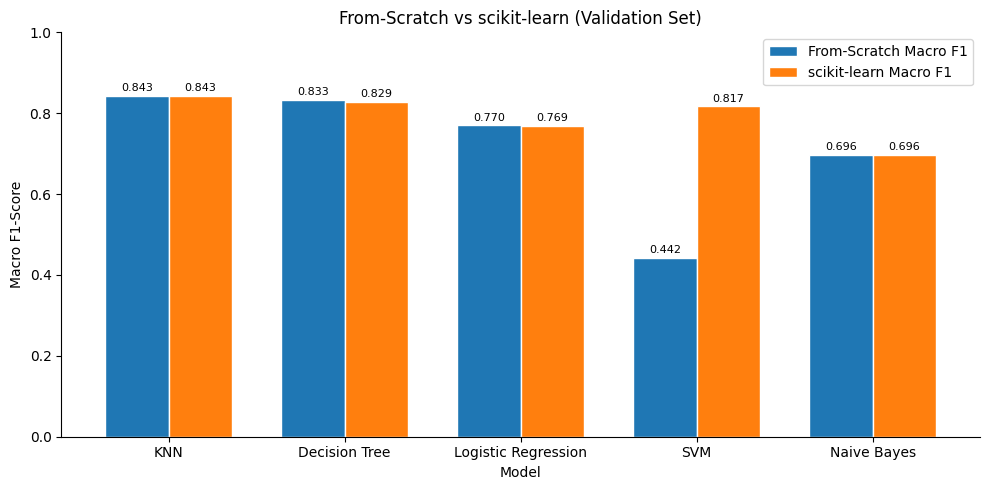

,Model,From-Scratch Macro F1,scikit-learn Macro F1,Difference
0,KNN,0.84302,0.84302,-0.00000
1,Decision Tree,0.83294,0.82886,0.00408
2,Logistic Regression,0.77009,0.76930,0.00079
3,SVM,0.44159,0.81681,-0.37522
4,Naive Bayes,0.69620,0.69620,-0.00000


In [16]:
def compare_sklearn(sk_models: dict, X_va_np: np.ndarray, y_va: pd.Series, scratch_df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for name, clf in sk_models.items():
        sk_f1 = f1_score(y_va, clf.predict(X_va_np), average='macro')
        sm_f1 = float(scratch_df.loc[scratch_df['Model'] == name, 'Macro F1'].iloc[0])
        rows.append({
            'Model': name,
            'From-Scratch Macro F1': round(sm_f1, 5),
            'scikit-learn Macro F1': round(sk_f1, 5),
            'Difference': round(sm_f1 - sk_f1, 5),
        })

    comp_df = pd.DataFrame(rows)
    ax = comp_df.set_index('Model')[['From-Scratch Macro F1', 'scikit-learn Macro F1']].plot(
        kind='bar', figsize=(10, 5), rot=0, width=0.72, edgecolor='white',
    )
    for container in ax.containers:
        ax.bar_label(container, fmt='%.3f', fontsize=8, padding=2)
    ax.set_ylabel('Macro F1-Score')
    ax.set_ylim(0, 1.0)
    ax.set_title('From-Scratch vs scikit-learn (Validation Set)')
    sns.despine(ax=ax)
    plt.tight_layout()
    plt.show()
    return comp_df

comparison_df = compare_sklearn(sklearn_models, X_val_prep.to_numpy(), y_val, scratch_results)
display(comparison_df)

---

# 9. Saving and Loading Models <a name="9"></a>

---

In [17]:
def save_model(model_name: str, model, prep, model_dir: Path) -> tuple[Path, Path]:
    slug = model_name.lower().replace(' ', '_')
    model_path = Path(model.save(f'best_{slug}'))
    prep_path = model_dir / 'preprocessor.pkl'
    with open(prep_path, 'wb') as f:
        pickle.dump(prep, f)
    print(f'Saved {model_name} -> {model_path}')
    return model_path, prep_path

def load_model(model_cls, model_path: Path, prep_path: Path):
    model = model_cls.load(Path(model_path).stem)
    with open(prep_path, 'rb') as f:
        prep = pickle.load(f)
    print(f'Loaded {model_cls.__name__} <- {model_path}')
    return model, prep

saved_model_path, saved_prep_path = save_model(
    BEST_MODEL_NAME, scratch_models[BEST_MODEL_NAME], preprocessor, CFG.MODEL_DIR
)
loaded_model, loaded_prep = load_model(type(scratch_models[BEST_MODEL_NAME]), saved_model_path, saved_prep_path)

Saved KNN -> /content/drive/MyDrive/Tubes2_Aibou/output/saved_models/best_knn.json
Loaded KNN <- /content/drive/MyDrive/Tubes2_Aibou/output/saved_models/best_knn.json


---

# 10. Kaggle Submission <a name="10"></a>

---

In [18]:
def make_submission(model_name: str, model_key: str, X_full_df, y_full_ser, X_test_df, test_ids, out_path: Path) -> pd.DataFrame:
    prep = make_preprocessor(X_full_df)
    X_full_np = prep.fit_transform(X_full_df)
    X_test_np = prep.transform(X_test_df)

    model = build_scratch_model(model_key, ACTIVE_PARAMS[model_key])
    if model_key == 'nb':
        cols = list(prep.get_feature_names_out())
        model.fit(pd.DataFrame(X_full_np, columns=cols), y_full_ser.reset_index(drop=True))
        preds = model.predict(pd.DataFrame(X_test_np, columns=cols))
    else:
        model.fit(X_full_np, y_full_ser.to_numpy())
        preds = model.predict(X_test_np)

    sub = pd.DataFrame({
        CFG.ID_COLUMN: test_ids.astype(str).values,
        CFG.TARGET_COLUMN: np.asarray(preds, dtype=int),
    })
    assert len(sub) == len(test_ids), 'Jumlah baris submission tidak sesuai!'
    assert sub.isna().sum().sum() == 0, 'Submission mengandung NaN!'
    assert (sub[CFG.ID_COLUMN].values == test_ids.astype(str).values).all(), 'Urutan ID berubah!'

    sub.to_csv(out_path, index=False)
    print(f'Submission ({model_name}) saved -> {out_path} | Shape: {sub.shape}')
    print(sub[CFG.TARGET_COLUMN].value_counts(normalize=True).round(4))
    return sub

submission_df = make_submission(
    BEST_MODEL_NAME, BEST_MODEL_KEY, X_full, y_full, X_test, test_df[CFG.ID_COLUMN], CFG.OUTPUT_DIR / 'submission.csv'
)
display(submission_df.head())

Submission (KNN) saved -> /content/drive/MyDrive/Tubes2_Aibou/output/submission.csv | Shape: (6844, 2)
is_canceled
0    0.7034
1    0.2966
Name: proportion, dtype: float64


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


---

# 11. Error Analysis <a name="11"></a>

---

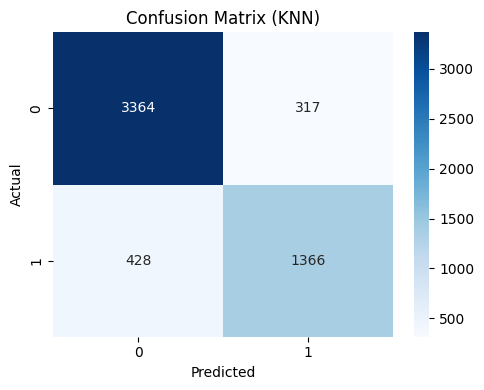

Validation Accuracy : 0.8639
Validation Macro F1 : 0.8430


,count,mean
booking_channel,,
Airline,16,0.1875
Complimentary,58,0.0345
Corporate,309,0.0777
Offline Agent,1573,0.0725
Online Travel Agent,3519,0.1711


In [19]:
def error_analysis(val_raw_df: pd.DataFrame, y_true: pd.Series, y_pred: np.ndarray, model_name: str) -> None:
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(f'Confusion Matrix ({model_name})')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    plt.tight_layout()
    plt.show()

    df_err = val_raw_df.reset_index(drop=True).copy()
    df_err['actual'] = y_true.to_numpy()
    df_err['pred'] = np.asarray(y_pred, dtype=int)
    df_err['is_error'] = (df_err['actual'] != df_err['pred']).astype(int)

    print(f'Validation Accuracy : {accuracy_score(y_true, y_pred):.4f}')
    print(f'Validation Macro F1 : {f1_score(y_true, y_pred, average="macro"):.4f}')
    display(df_err.groupby('booking_channel', dropna=False)['is_error'].agg(['count', 'mean']).round(4))

error_analysis(X_val_raw, y_val, scratch_preds[BEST_MODEL_NAME], BEST_MODEL_NAME)